### В данной домашней работе Вам предстоит отработать следующие 2 навыка: работа с пропущенными значениями и анализ выбросов.

In [1]:
import numpy as np
import pandas as pd

data = pd.read_csv('processed_data_with_new_features.csv', index_col='id')

In [2]:
data.head()

,vendor_id,passenger_count,store_and_fwd_flag,distance_km,log_trip_duration,anomaly,traffic_jam,day_of_week_1,day_of_week_2,day_of_week_3,...,hour_19,hour_20,hour_21,hour_22,hour_23,month_2,month_3,month_4,month_5,month_6
id,,,,,,,,,,,,,,,,,,,,,
id2875421,1,930.399753,0,1.500479,6.122493,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
id2377394,0,930.399753,0,1.807119,6.498282,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
id3858529,1,NaN,0,6.392080,7.661527,0,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
id3504673,1,NaN,0,1.487155,6.063785,0,0,0,1,0,...,1,0,0,0,0,0,0,1,0,0
id2181028,1,930.399753,0,1.189925,6.077642,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0


Никудышный гном случайно пролил кофе на папку с данными и кодом. К несчастью, из-за этого они с братьями потеряли кучу информации в столбиках **passenger_count** и **distance_km**.

In [3]:
### Выведите количество пропусков в данных колонках
### На всякий случай, проверьте целостность данных в остальных

data.isna().sum()

vendor_id                  0
passenger_count       145864
store_and_fwd_flag         0
distance_km           145864
log_trip_duration          0
anomaly                    0
traffic_jam                0
day_of_week_1              0
day_of_week_2              0
day_of_week_3              0
day_of_week_4              0
day_of_week_5              0
day_of_week_6              0
hour_1                     0
hour_2                     0
hour_3                     0
hour_4                     0
hour_5                     0
hour_6                     0
hour_7                     0
hour_8                     0
hour_9                     0
hour_10                    0
hour_11                    0
hour_12                    0
hour_13                    0
hour_14                    0
hour_15                    0
hour_16                    0
hour_17                    0
hour_18                    0
hour_19                    0
hour_20                    0
hour_21                    0
hour_22       

Начнем с **passenger_count**. Вообще говоря, изначально это была категориальная колонка, к которой мы применили технику OneHotEncoder. Чтобы избавиться от пропусков в данных, конечно, можно просто убрать все объекты, в которых есть пропуски, но тогда мы потеряем ценную информацию. 

Воспользуйтесь относительно простым приемом из лекции: в указанной колонке заполните пропуски самым *популярным* значением среди неотсутствующих.

In [4]:
### Your code is here
popular_passenger_count = data['passenger_count'].value_counts().index[0]

data['passenger_count'] = data['passenger_count'].fillna(popular_passenger_count)


In [5]:
popular_passenger_count

np.float64(930.3997532751514)

С колонкой **distance_km** поступим более интересным способом!

Чтобы заполнить пропуск в данной колонке для того или иного объекта, можно находить наиболее похожий на него объект и подглядывать в его значение **distance_km**. Для того, чтобы понять, насколько объекты похожи друг на друга, необходимо использовать Евклидово расстояние между этими самыми объектами в пространстве всех признаков!

С учетом количества объектов в нашем датасете и признаков, посчитать попарные расстояния будет мега-сложно. Поэтому давайте называть объекты похожими, если они принадлежат одной категории, составленной из следующих колонок:

1. vendor_id
2. store_and_fwd_flag
3. traffic_jam
4. month_2
5. month_3
6. month_4
7. month_5
8. month_6

Внутри каждой группы найдите среднее значение признака **distance_km** и заполните NaN'ы в объектах с пропуском в соответствии с тем, к какой категории относится данный объект. Похожее упражнение мы делали на практике в занятии!

**Hint**: достаточно просто взять group by по указанным выше категориальным колонкам и верно вставить полученный результат в исходную табличку.

P.S. Колонки выбраны случайным образом. Можно было взять и другую комбинацию.

In [6]:
### Your code is here
mean_distance = data.groupby(['vendor_id','store_and_fwd_flag','traffic_jam','month_2','month_3','month_4','month_5','month_6'])['distance_km'].transform("mean")

data['distance_km'] = data['distance_km'].fillna(mean_distance)


In [7]:
### Убедимся, что пропусков не осталось

data.isna().sum()


vendor_id             0
passenger_count       0
store_and_fwd_flag    0
distance_km           0
log_trip_duration     0
anomaly               0
traffic_jam           0
day_of_week_1         0
day_of_week_2         0
day_of_week_3         0
day_of_week_4         0
day_of_week_5         0
day_of_week_6         0
hour_1                0
hour_2                0
hour_3                0
hour_4                0
hour_5                0
hour_6                0
hour_7                0
hour_8                0
hour_9                0
hour_10               0
hour_11               0
hour_12               0
hour_13               0
hour_14               0
hour_15               0
hour_16               0
hour_17               0
hour_18               0
hour_19               0
hour_20               0
hour_21               0
hour_22               0
hour_23               0
month_2               0
month_3               0
month_4               0
month_5               0
month_6               0
dtype: int64

In [9]:
data[:20].to_csv('data_7.csv', sep = ';', index=False)

### Теперь наши данные чисты! Замерьте качество модели на Кросс-Валидации

In [8]:
from sklearn.model_selection import KFold

selector = KFold(n_splits=4, shuffle=True, random_state=33)

from sklearn.model_selection import cross_validate
from sklearn.linear_model import LinearRegression

model = LinearRegression()

cross_val_error = cross_validate(
    model, 
    data.drop('log_trip_duration', axis=1), 
    data['log_trip_duration'], 
    cv=selector, 
    scoring='neg_mean_squared_error', 
    n_jobs=-1)
# ['test_score'].mean()

# print(f"MSLE на Кросс-валидации: {round(cross_val_error, 3)}")

In [9]:

print(f"MSLE на Кросс-валидации: {round(cross_val_error['test_score'].mean(), 3)}")

MSLE на Кросс-валидации: -0.431


### Проведем анализ выбросов! Нарисуйте ящик с усами и гистограмму для таргетной переменной.

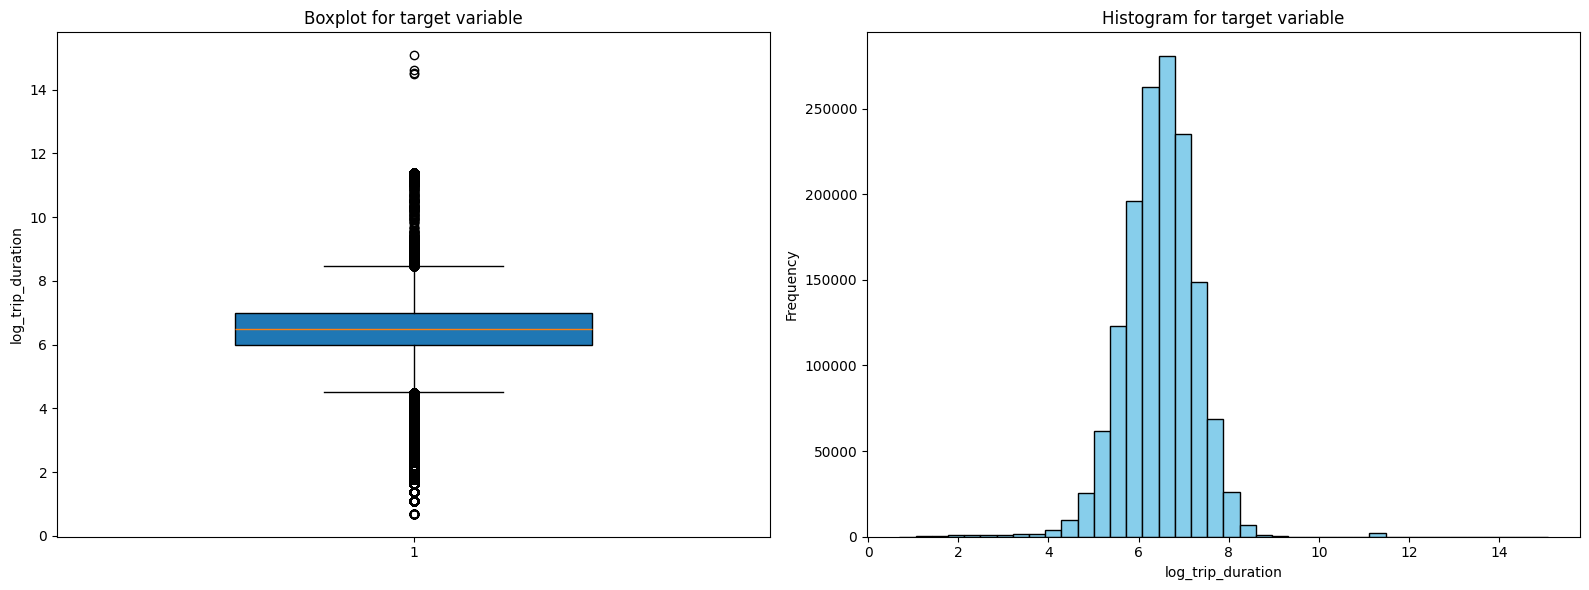

In [10]:
import matplotlib.pyplot as plt

target = data['log_trip_duration']

fig, axes = plt.subplots(1,2, figsize=(16, 6))

axes[0].boxplot(target, vert=True, patch_artist=True, widths=0.5)
axes[0].set_title('Boxplot for target variable')
axes[0].set_ylabel('log_trip_duration')

axes[1].hist(target, bins=40, color='skyblue', edgecolor='black')
axes[1].set_title('Histogram for target variable')
axes[1].set_xlabel('log_trip_duration')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()



Есть ли, на ваш взгляд, в данных выбросы?

Кажется, что да!

Давайте почистим их, удалив те объекты, таргеты которых находятся вне промежутка

(топ 99,5% значение;   топ 0,5% значение)

In [ ]:
### Your code is here
# q_low = data['log_trip_duration'].quantile(0.005)
# q_high = data['log_trip_duration'].quantile(0.995)
# data_new = data[(data['log_trip_duration'] >= q_low) & (data['log_trip_duration'] <= q_high)]

Снова замерьте качество на кросс-валидации, используя старый selector

In [ ]:
### Your code is here
# cross_val_error = cross_validate(
#     model, 
#     data_new.drop('log_trip_duration', axis=1), 
#     data_new['log_trip_duration'], 
#     cv=selector, 
#     scoring='neg_mean_squared_error', 
#     n_jobs=-1)['test_score'].mean()

# print(f"MSLE на Кросс-валидации: {round(cross_val_error, 3)}")


MSLE на Кросс-валидации: -0.342


In [14]:
target = data['log_trip_duration']

lower_bound = target.quantile(0.005)
upper_bound = target.quantile(0.995)

mask = (target > lower_bound) & (target < upper_bound)

data_without_outliers = data[mask].copy()

In [15]:
print(f"До очистки: {data.shape[0]}")
print(f"После очистки: {data_without_outliers.shape[0]}")
print(f"Удалено: {data.shape[0] - data_without_outliers.shape[0]}")

До очистки: 1458644
После очистки: 1444013
Удалено: 14631


In [16]:
model = LinearRegression()

cross_val_error = cross_validate(
    model, 
    data_without_outliers.drop('log_trip_duration', axis=1), 
    data_without_outliers['log_trip_duration'], 
    cv=selector, 
    scoring='neg_mean_squared_error', 
    n_jobs=-1)['test_score'].mean()

print(f"MSLE на Кросс-валидации: {round(cross_val_error, 3)}")

MSLE на Кросс-валидации: -0.35
